In [1]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing import event_accumulator
from pathlib import Path
import os
from tqdm import tqdm
from matplotlib.ticker import PercentFormatter, FuncFormatter
import glob
from concurrent.futures import ProcessPoolExecutor
from tensorboard.backend.event_processing.event_file_loader import EventFileLoader
from tensorboard.util import tensor_util
from tb_loader import load_file
from scipy.stats import ttest_ind, false_discovery_control
from matplotlib.patches import Ellipse

In [2]:
IMPORTANT_STATS_NAMES = {
    "reward/mean": "Reward per timestep",
    "observation/progress_per_second": "Progress per second",
    "observation/forward_velocity": "Forward velocity",
    "observation/progress_metres": "Progress per episode",
    "collision/per_progress_metres": "Collisions per progress metre",
    "collision/per_episode": "Collisions per episode",
    "collision/per_step": "Collisions per step",
}

IMPORTANT_STATS = [key for key in IMPORTANT_STATS_NAMES.keys()]

MOST_IMPORTANT_STATS = [
    "observation/progress_metres",
    "collision/per_progress_metres"
]

In [3]:
def load_runs(logdir="runs", tags=None):
    tags = set(tags) if tags is not None else None
    jobs = []
    for model_name in os.listdir(logdir):
      for f in sorted(glob.glob(f"{logdir}/{model_name}/**/*tfevents*", recursive=True)):
          jobs.append((f, model_name, tags))

    with ProcessPoolExecutor() as pool:
        return pd.concat(pool.map(load_file, jobs), ignore_index=True)
                                 # all tags
if os.path.exists("results/tensorboard_data.pkl"):
    df = pd.read_pickle("results/tensorboard_data.pkl")
else:
    df = load_runs(tags=IMPORTANT_STATS)        # only these
    df.to_pickle("results/tensorboard_data.pkl")


In [4]:
data = df

In [5]:
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data = data.sort_values("wall_time").drop_duplicates(["run_name", "step", "tag"], keep="last")
data = data.sort_values("step")

In [6]:
data_pivot = data.pivot(index=["step", "run_category", "run_seed", "aux_weight"], columns="tag", values="value")
data_pivot["collision/per_progress_metres"] = data_pivot["collision/per_step"] / data_pivot["observation/progress_metres"]
data_pivot["observation/progress_per_second"] = data_pivot["observation/progress_metres"] * 25
data_pivot = data_pivot.reset_index()
#data_pivot = data_pivot[~data_pivot["run_category"].str.startswith("rnn_")]
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second
0,0.0,all,s0,0.1,1.000000,0.001139,0.055985,0.002144,0.000996,0.531435,0.053597
1,0.0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,0.498418,0.048983
2,0.0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,0.471998,0.051725
3,0.0,all,s1,0.1,1.000000,0.001628,-0.025569,-0.000988,-0.002604,-1.646567,-0.024712
4,0.0,all,s1,0.3,1.000000,0.001058,-0.024407,-0.000804,-0.001854,-1.315935,-0.020099
...,...,...,...,...,...,...,...,...,...,...,...
184106,599.0,wheel_slip_rear_lateral,s4,0.3,0.901961,0.003743,2.121085,0.089808,0.085815,0.041683,2.245200
184107,599.0,wheel_slip_rear_lateral,s4,1,0.125000,0.000081,4.149317,0.174634,0.174548,0.000466,4.365861
184108,599.0,wheel_slip_rear_lateral,s5,0.1,0.708333,0.001383,0.874415,0.036265,0.034834,0.038149,0.906622
184109,599.0,wheel_slip_rear_lateral,s5,0.3,0.250000,0.000244,3.803875,0.161202,0.160941,0.001515,4.030049


In [7]:

RUN_COLUMNS = ["run_category", "run_seed", "aux_weight"]

In [8]:
auc_df = (
    data_pivot.sort_values("step")
    .groupby(RUN_COLUMNS)[IMPORTANT_STATS + ["step"]]
    .apply(lambda g: pd.Series(
        np.trapezoid(g[IMPORTANT_STATS].to_numpy(), g["step"].to_numpy(), axis=0),
        index=IMPORTANT_STATS,
    ))
)
auc_df = auc_df.reset_index()

last_50 = data_pivot.sort_values("step").groupby(RUN_COLUMNS).tail(50)
last_50_means = last_50.groupby(RUN_COLUMNS)[IMPORTANT_STATS].mean()
last_50_means["collision/per_progress_metres"] = (
    last_50_means["collision/per_step"] / last_50_means["observation/progress_metres"]
)
last_50_means["observation/progress_per_second"] = last_50_means["observation/progress_metres"] * 25
last_50_means = last_50_means[IMPORTANT_STATS].reset_index()

/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/Users/jacquesamsel/.pyenv/versions/skripsie/lib/python3.10/site-packages/seaborn/categorical.py:3399: UserWarning: 16.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


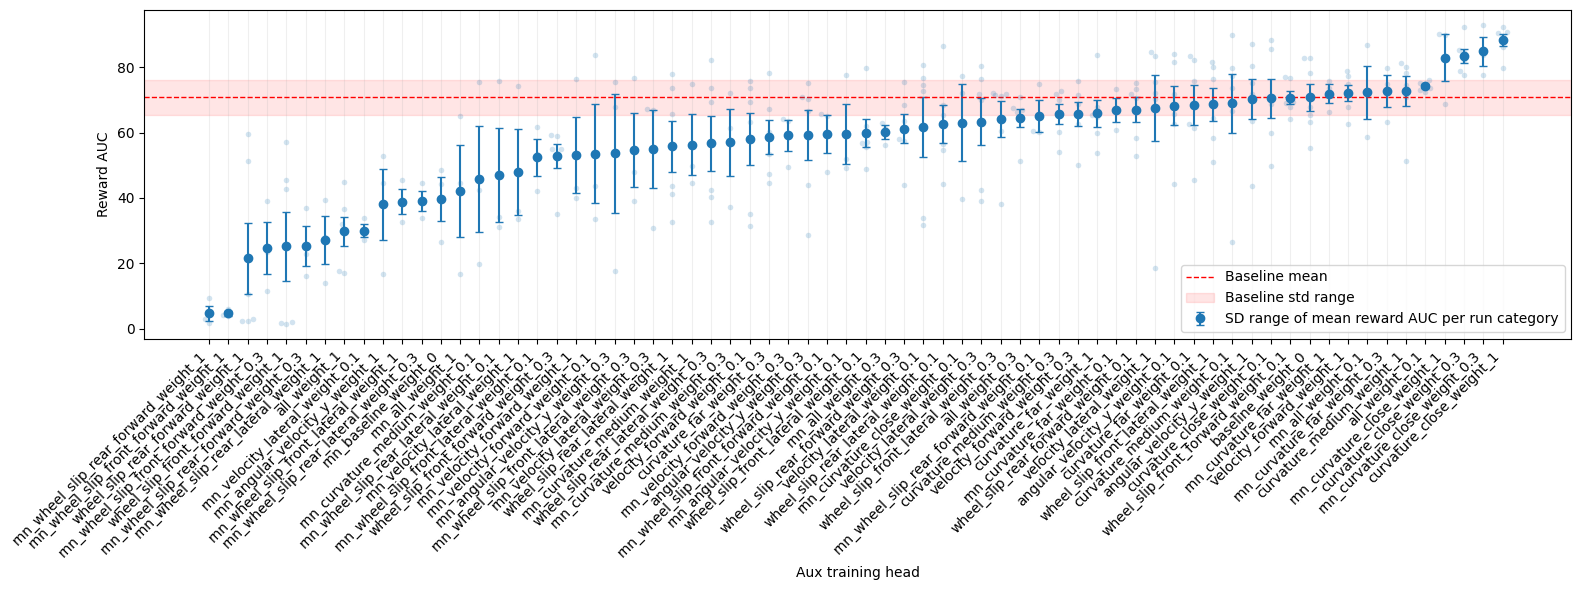

In [9]:
STAT = "reward/mean"

to_show = auc_df.sort_values(STAT)

to_show["label"] = to_show["run_category"] + \
    "_weight_" + to_show["aux_weight"].astype(str)

to_show_means = to_show.groupby(
    "label")[STAT].agg(["mean", "std", "sem"]).reset_index().sort_values("mean")

base_mean = to_show[to_show["run_category"] == "baseline"][STAT].mean()
base_std = to_show_means[to_show_means["label"].str.contains("baseline")]["sem"].mean()

order = to_show_means["label"].tolist()

plt.figure(figsize=(16, 6))

plt.errorbar(
    to_show_means["label"],
    to_show_means["mean"],
    yerr=to_show_means["sem"],
    fmt="o",
    capsize=3,
    label="SD range of mean reward AUC per run category"
)
sns.swarmplot(
    data=to_show,
    x="label",
    y=STAT,
    order=order,
    legend=False,
    s=4,
    alpha=0.2
).set(xlabel="Aux training head", ylabel="Reward AUC")

sns.scatterplot(
    data=to_show_means,
    x="label",
    y="mean"
)

plt.grid(True, axis="x", alpha=0.2)

plt.axhline(base_mean, color="red", ls="--", lw=1, label="Baseline mean")
plt.axhspan(base_mean - base_std, base_mean + base_std,
            color="red", alpha=0.1, label="Baseline std range")

plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("results/figures/auc_comparison.pdf", bbox_inches="tight")

In [10]:
baseline = last_50_means.loc[last_50_means["run_category"] == "baseline", IMPORTANT_STATS]

last_50_means_ttest_results = (
    last_50_means[last_50_means["run_category"] != "baseline"]
    .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
    .apply(lambda g: pd.Series(ttest_ind(g, baseline, equal_var=False).pvalue, index=IMPORTANT_STATS))
)

last_50_means_ttest_results = pd.DataFrame(false_discovery_control(last_50_means_ttest_results), columns=last_50_means_ttest_results.columns, index=last_50_means_ttest_results.index)


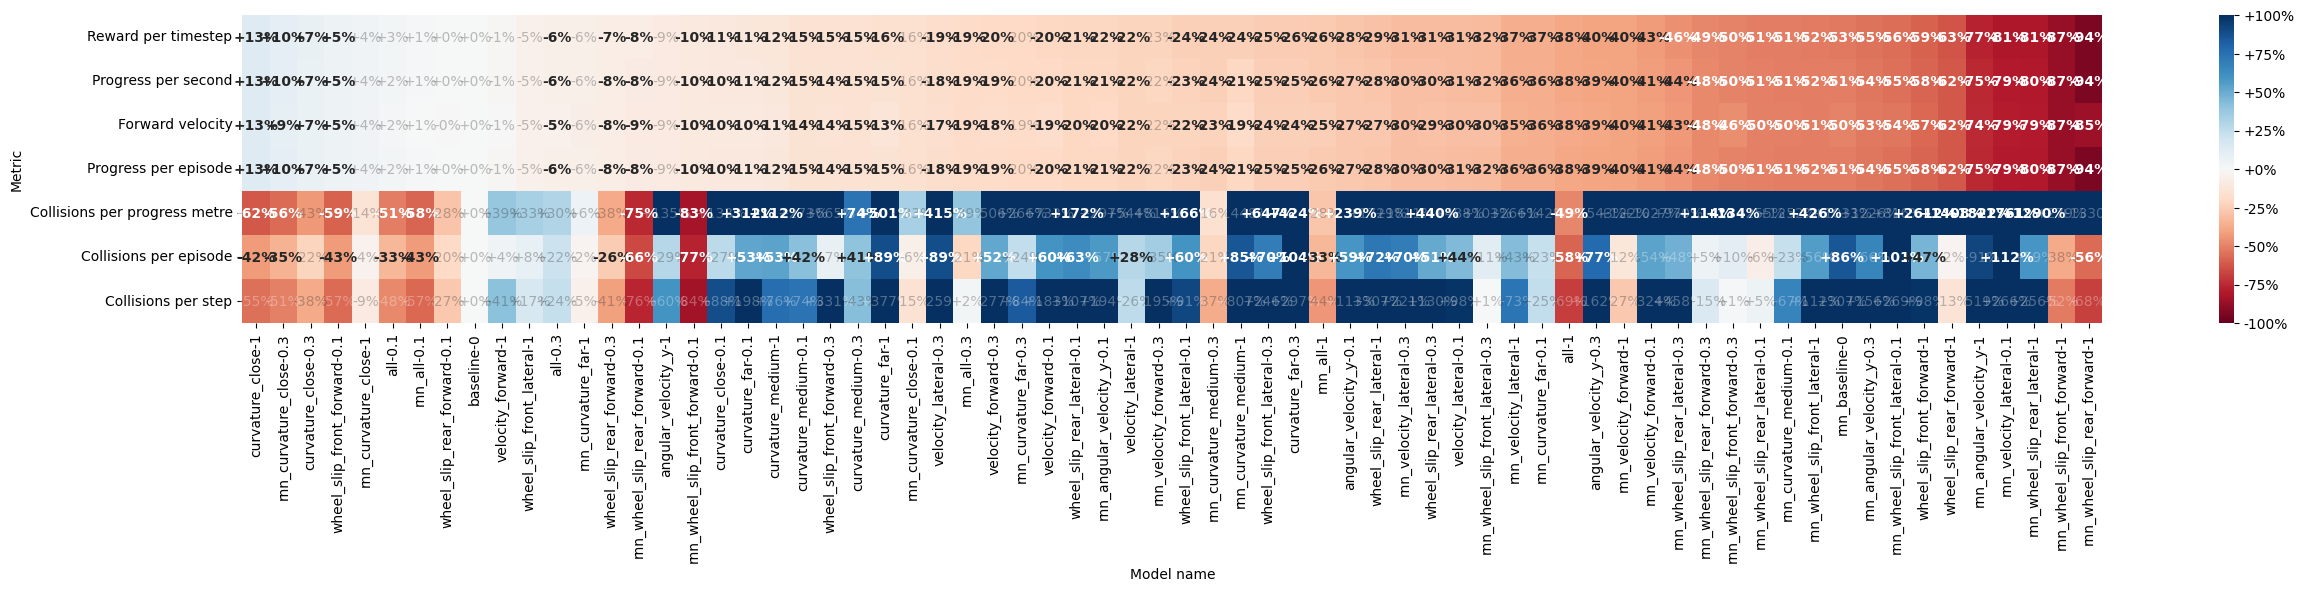

In [11]:
ALPHA = 0.5

to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().sort_values("reward/mean", ascending=False)
baseline = to_show.loc["baseline"].squeeze()

to_show = to_show.div(baseline, axis=1) - 1

sig = (last_50_means_ttest_results < ALPHA).T.reindex(
    index=to_show.T.index, columns=to_show.T.columns, fill_value=False
)

plt.figure(figsize=(30, 4))

ax = sns.heatmap(
    to_show.rename(columns=IMPORTANT_STATS_NAMES).T,
    annot=True,
    fmt="+.0%",
    cmap="RdBu",
    center=0,
    vmax=1.0,
    vmin=-1.0,
    cbar_kws={"format": FuncFormatter(lambda x, _: f"{x:+.0%}")},
)
ax.set(xlabel="Model name", ylabel="Metric")

for t in ax.texts:
    x, y = t.get_position()
    if sig.iat[int(y - 0.5), int(x - 0.5)]:
        t.set_fontweight("bold")
    else:
        t.set_alpha(0.3)

plt.savefig("results/figures/last_50_means_heatmap.pdf", bbox_inches="tight")

In [12]:
last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].agg(["mean", "std"]).loc["rnn_baseline"]

tag        reward/mean           observation/progress_per_second            \
                  mean       std                            mean       std   
aux_weight                                                                   
0             0.078021  0.029995                        2.007584  0.692739   

tag        observation/forward_velocity           observation/progress_metres  \
                                   mean       std                        mean   
aux_weight                                                                      
0                              1.931944  0.659818                    0.080303   

tag                 collision/per_progress_metres            \
                std                          mean       std   
aux_weight                                                    
0           0.02771                      0.038162  0.049979   

tag        collision/per_episode           collision/per_step            
                            mean       std               mean       std  
aux_weight                                                               
0                        0.67429  0.236807           0.002186  0.002299

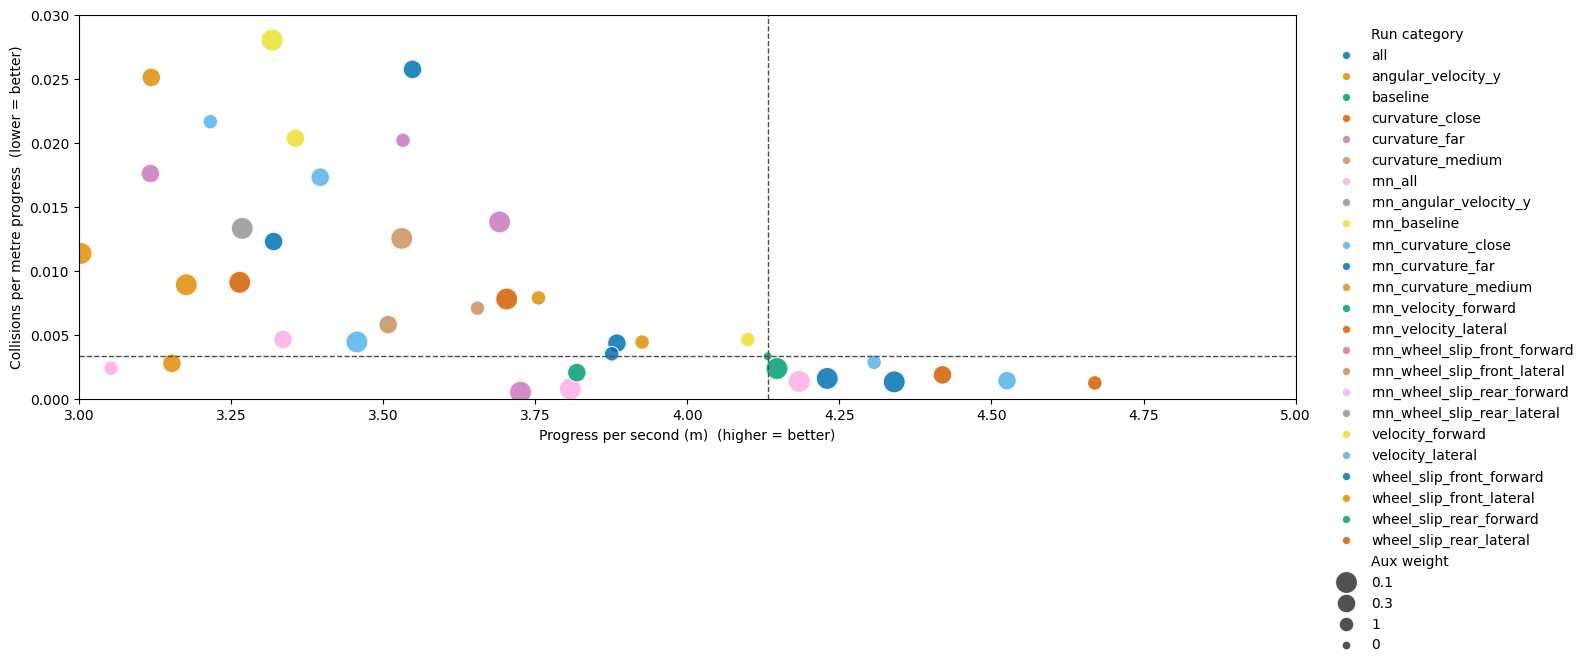

In [13]:
x_col = "observation/progress_per_second"
y_col = "collision/per_progress_metres"

to_show = last_50_means.groupby(["run_category", "aux_weight"])[IMPORTANT_STATS].mean().reset_index()

baseline = to_show[to_show["run_category"] == "baseline"]
bx, by = baseline[x_col].mean(), baseline[y_col].mean()



fig, ax = plt.subplots(figsize=(16, 6))

sns.scatterplot(
    data=to_show.rename(columns={"run_category": "Run category", "aux_weight": "Aux weight"}),
    x=x_col,
    y=y_col,
    hue="Run category",
    size="Aux weight",
    sizes=(40, 250),
    palette="colorblind",
    alpha=0.85,
    edgecolor="white",
    legend="full",
    ax=ax,
).set()

to_show_grp = last_50_means.set_index(["run_category", "aux_weight"])

# Baseline reference crosshair (dark grey so it doesn't clash with the palette)
ax.axhline(by, color="0.3", ls="--", lw=1)
ax.axvline(bx, color="0.3", ls="--", lw=1)
ax.annotate("baseline mean", (0.2, by), xytext=(-4, 5),
            textcoords="offset points", ha="right", fontsize=9, color="0.3")

ax.set(
    xlim=(3, 5),
    ylim=(0, 0.03),
    xlabel="Progress per second (m)  (higher = better)",
    ylabel="Collisions per metre progress  (lower = better)"
)

ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/progress_vs_collision.pdf", bbox_inches="tight")

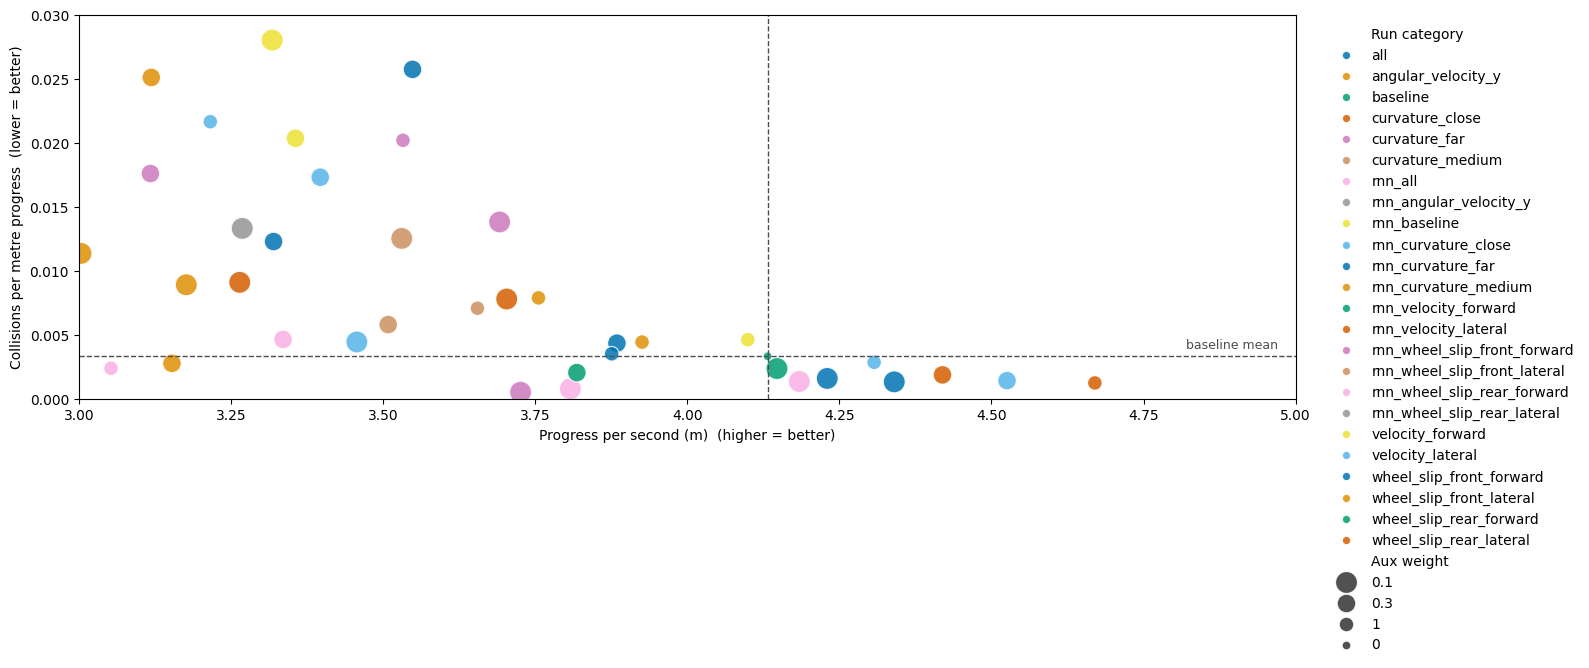

In [14]:
from scipy.stats import chi2
from matplotlib.patches import Ellipse

x_col = "observation/progress_per_second"
y_col = "collision/per_progress_metres"

cats = sorted(last_50_means["run_category"].unique())
palette = dict(zip(cats, sns.color_palette("colorblind", len(cats))))

to_show = (last_50_means
           .groupby(["run_category", "aux_weight"])[IMPORTANT_STATS]
           .mean().reset_index())

baseline = to_show[to_show["run_category"] == "baseline"]
bx, by = baseline[x_col].mean(), baseline[y_col].mean()

fig, ax = plt.subplots(figsize=(16, 6))
sns.scatterplot(
    data=to_show.rename(columns={"run_category": "Run category", "aux_weight": "Aux weight"}),
    x=x_col, y=y_col,
    hue="Run category", size="Aux weight", sizes=(40, 250),
    palette=palette, alpha=0.85, edgecolor="white", legend="full", ax=ax,
)

k = np.sqrt(chi2.ppf(0.95, df=2))  # ~2.448 for a 95% region in 2D

# for (run_category, aux_weight), g in last_50_means.groupby(["run_category", "aux_weight"]):
#     pts = g[[x_col, y_col]].dropna()
#     if len(pts) < 3:
#         continue
#     mean = pts.mean().to_numpy()
#     cov = pts.cov().to_numpy()
#     eigvals, eigvecs = np.linalg.eigh(cov)          # ascending
#     order = eigvals.argsort()[::-1]                  # largest first
#     eigvals, eigvecs = eigvals[order], eigvecs[:, order]
#     if eigvals[0] > 0.1:
#         continue
#     ax.add_patch(Ellipse(
#         xy=mean,
#         width=2 * np.sqrt(eigvals[0]),
#         height=2 * np.sqrt(eigvals[1]),
#         angle=np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0])),
#         fill=False, edgecolor=palette[run_category], lw=1, alpha=0.6,
#     ))

ax.axhline(by, color="0.3", ls="--", lw=1)
ax.axvline(bx, color="0.3", ls="--", lw=1)
ax.annotate("baseline mean", xy=(0.99, by), xycoords=("axes fraction", "data"),
            xytext=(-4, 5), textcoords="offset points",
            ha="right", fontsize=9, color="0.3")

ax.set(xlim=(3, 5), ylim=(0, 0.03),
       xlabel="Progress per second (m)  (higher = better)",
       ylabel="Collisions per metre progress  (lower = better)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.savefig("results/figures/progress_vs_collision.pdf", bbox_inches="tight")

In [15]:
keys = ["run_category", "aux_weight"]

med = last_50_means.groupby(keys)["reward/mean"].transform("median")
dist = (last_50_means["reward/mean"] - med).abs()

median_rows = (
    last_50_means.assign(_dist=dist)
    .sort_values("_dist", kind="stable")
    .groupby(keys, as_index=False)
    .head(1)
    .drop(columns="_dist")
    .sort_values(keys)
    .reset_index(drop=True)
)
median_rows

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,observation/progress_metres,collision/per_progress_metres,collision/per_episode,collision/per_step
0,all,s2,0.1,0.168969,4.231395,3.974511,0.169256,0.001539,0.229055,0.000260
1,all,s3,0.3,0.153837,3.865749,3.696238,0.154630,0.004621,0.507017,0.000715
2,all,s4,1,0.090521,2.267021,2.107351,0.090681,0.001597,0.133462,0.000145
3,angular_velocity_y,s0,0.1,0.133512,3.359346,3.134266,0.134374,0.006105,0.563055,0.000820
4,angular_velocity_y,s5,0.3,0.112084,2.836902,2.664932,0.113476,0.011933,0.700639,0.001354
...,...,...,...,...,...,...,...,...,...,...
63,wheel_slip_rear_forward,s0,0.3,0.158650,3.975816,3.722913,0.159033,0.002211,0.291382,0.000352
64,wheel_slip_rear_forward,s5,1,0.012602,0.330054,0.323720,0.013202,0.044875,0.458412,0.000592
65,wheel_slip_rear_lateral,s0,0.1,0.127870,3.231728,3.027955,0.129269,0.010450,0.669416,0.001351
66,wheel_slip_rear_lateral,s2,0.3,0.098033,2.493258,2.366499,0.099730,0.016483,0.741927,0.001644


In [16]:
data_pivot["run_seed"]

0         s0
1         s0
2         s0
3         s1
4         s1
          ..
184106    s4
184107    s4
184108    s5
184109    s5
184110    s5
Name: run_seed, Length: 184111, dtype: object

<Axes: xlabel='collision/per_progress_metres', ylabel='observation/progress_per_second'>

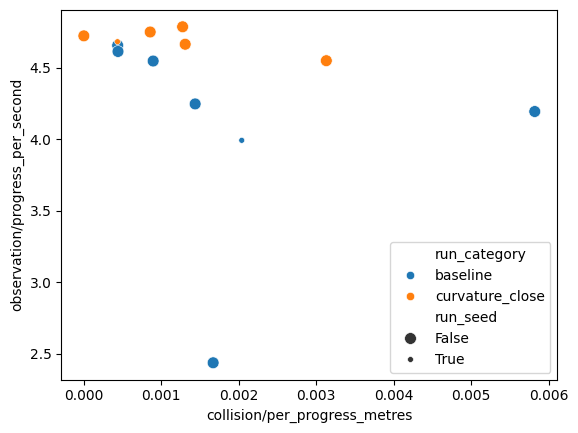

In [17]:
to_show = data_pivot[(data_pivot["run_category"].isin(["baseline", "curvature_close"])) & (data_pivot["step"] == 599.0) & (data_pivot["aux_weight"].isin(["0", "1"]))]

sns.scatterplot(
    data=to_show,
    hue="run_category",
    x="collision/per_progress_metres",
    size=to_show["run_seed"].isin(["s2"]),
    y="observation/progress_per_second"
)

In [18]:
last_50_means

tag,run_category,run_seed,aux_weight,reward/mean,observation/progress_per_second,observation/forward_velocity,observation/progress_metres,collision/per_progress_metres,collision/per_episode,collision/per_step
0,all,s0,0.1,0.175062,4.382294,4.091511,0.175292,0.001133,0.193132,0.000199
1,all,s0,0.3,0.162019,4.061126,3.783238,0.162445,0.002485,0.312783,0.000404
2,all,s0,1,0.103041,2.577936,2.365458,0.103117,0.000663,0.075912,0.000068
3,all,s1,0.1,0.161085,4.033868,3.768374,0.161355,0.001503,0.224590,0.000243
4,all,s1,0.3,0.171508,4.296201,4.017535,0.171848,0.001828,0.265081,0.000314
...,...,...,...,...,...,...,...,...,...,...
302,wheel_slip_rear_lateral,s4,0.3,0.067599,1.779842,1.716670,0.071194,0.048992,0.929794,0.003488
303,wheel_slip_rear_lateral,s4,1,0.170777,4.281844,4.050769,0.171274,0.002575,0.345189,0.000441
304,wheel_slip_rear_lateral,s5,0.1,0.095827,2.427968,2.277983,0.097119,0.013005,0.688965,0.001263
305,wheel_slip_rear_lateral,s5,0.3,0.147494,3.700960,3.530883,0.148038,0.003353,0.393763,0.000496


<Axes: xlabel='collision/per_progress_metres', ylabel='observation/progress_per_second'>

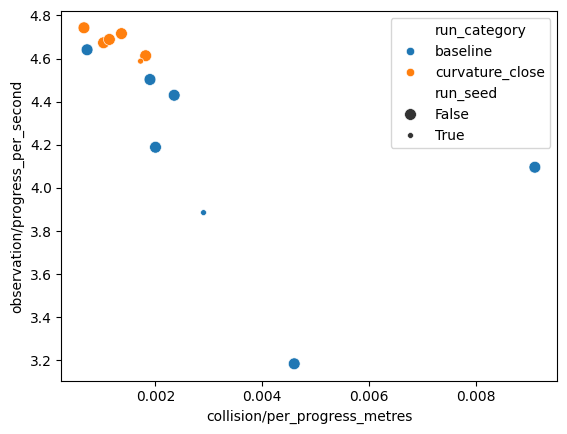

In [19]:
to_show = last_50_means[(last_50_means["run_category"].isin(["baseline", "curvature_close"])) & (last_50_means["aux_weight"].isin(["0", "1"]))]

sns.scatterplot(
    data=to_show,
    hue="run_category",
    x="collision/per_progress_metres",
    size=to_show["run_seed"].isin(["s2"]),
    y="observation/progress_per_second"
)

In [20]:
data_pivot

tag,step,run_category,run_seed,aux_weight,collision/per_episode,collision/per_step,observation/forward_velocity,observation/progress_metres,reward/mean,collision/per_progress_metres,observation/progress_per_second
0,0.0,all,s0,0.1,1.000000,0.001139,0.055985,0.002144,0.000996,0.531435,0.053597
1,0.0,all,s0,0.3,1.000000,0.000977,0.053421,0.001959,0.000972,0.498418,0.048983
2,0.0,all,s0,1,1.000000,0.000977,0.055088,0.002069,0.001084,0.471998,0.051725
3,0.0,all,s1,0.1,1.000000,0.001628,-0.025569,-0.000988,-0.002604,-1.646567,-0.024712
4,0.0,all,s1,0.3,1.000000,0.001058,-0.024407,-0.000804,-0.001854,-1.315935,-0.020099
...,...,...,...,...,...,...,...,...,...,...,...
184106,599.0,wheel_slip_rear_lateral,s4,0.3,0.901961,0.003743,2.121085,0.089808,0.085815,0.041683,2.245200
184107,599.0,wheel_slip_rear_lateral,s4,1,0.125000,0.000081,4.149317,0.174634,0.174548,0.000466,4.365861
184108,599.0,wheel_slip_rear_lateral,s5,0.1,0.708333,0.001383,0.874415,0.036265,0.034834,0.038149,0.906622
184109,599.0,wheel_slip_rear_lateral,s5,0.3,0.250000,0.000244,3.803875,0.161202,0.160941,0.001515,4.030049


[None]

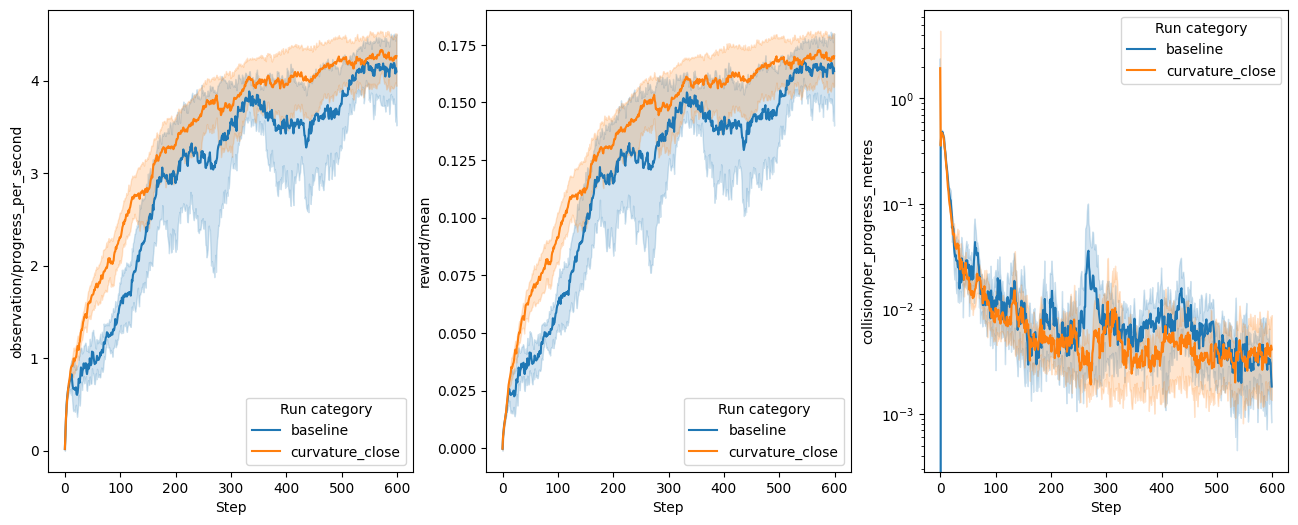

In [21]:
to_show = data_pivot[(data_pivot["run_category"].isin(["curvature_close", "baseline"]))]

fig, axs = plt.subplots(1, 3, figsize=(16, 6))
sns.lineplot(
    data=to_show.rename(columns={"run_category": "Run category", "step": "Step"}),
    hue="Run category",
    x="Step",
    y="observation/progress_per_second",
    ax=axs[0]
)
sns.lineplot(
    data=to_show.rename(columns={"run_category": "Run category", "step": "Step"}),
    hue="Run category",
    x="Step",
    y="reward/mean",
    ax=axs[1]
)
sns.lineplot(
    data=to_show.rename(columns={"run_category": "Run category", "step": "Step"}),
    hue="Run category",
    x="Step",
    y="collision/per_progress_metres",
    ax=axs[2]
).set(yscale="log")